# Trích Xuất & Trực Quan Hóa 5 Góc Nhìn Dữ Liệu (5-Views Multi-View Pipeline)

Notebook này thực hiện:
1. Nạp mẫu ảnh từ tập dữ liệu **Oxford-IIIT Pet**.
2. Áp dụng quy trình tiền xử lý để **trích xuất và in ra trực quan 5 góc nhìn (5 Views)** của từng mẫu ảnh:
   * **View 1 (Raw View):** Ảnh gốc ban đầu.
   * **View 2 (Denoised View):** Lọc khử nhiễu song phương (*Bilateral Filter* $d=9, \sigma=75$).
   * **View 3 (Contrast View):** Cân bằng tương phản thích ứng trên kênh L trong không gian màu LAB (*CLAHE on L-channel*).
   * **View 4 (Combined View):** Pipeline kết hợp tuần tự (*Bilateral Denoise $\to$ CLAHE LAB*).
   * **View 5 (Geometric View):** Pipeline kết hợp + Lật ngang + Xoay nghiêng $+15^\circ$.
3. Chạy qua nhiều mẫu ảnh thú cưng khác nhau và so sánh kết quả suy diễn phân loại Zero-Shot của mô hình **CLIP (`openai/clip-vit-base-patch32`)**.

In [1]:
import os
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
import PIL.Image
from PIL import Image
from torchvision.datasets import OxfordIIITPet
from transformers import CLIPModel, CLIPProcessor

# 1. Cấu hình thiết bị tính toán
device = torch.device("mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu"))
print(f"Đang sử dụng thiết bị: {device}")

# 2. Tự động xác định đường dẫn thư mục dataset
dataset_root = "../dataset"
for p in ["../dataset", "../../dataset", "dataset", ".", "../../../dataset"]:
    if os.path.exists(os.path.join(p, "oxford-iiit-pet")):
        dataset_root = p
        break

print(f"Thư mục gốc của dataset: {os.path.abspath(dataset_root)}")

# 3. Nạp dataset Oxford-IIIT Pet
pets_test = OxfordIIITPet(root=dataset_root, download=False, split="test")
class_names = pets_test.classes
print(f"Nạp thành công tập test gồm {len(pets_test)} ảnh, {len(class_names)} giống chó mèo.")

# 4. Khởi tạo mô hình và processor CLIP
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
model.eval()
print("Mô hình CLIP đã sẵn sàng!")


Đang sử dụng thiết bị: mps
Thư mục gốc của dataset: /Users/nguyenhuuhoangluan/Git_Code/CLIP-Animal-Classifier/dataset
Nạp thành công tập test gồm 3669 ảnh, 37 giống chó mèo.
Mô hình CLIP đã sẵn sàng!


In [2]:
# ==============================================================================
# CÁC HÀM TIỀN XỬ LÝ ẢNH & SINH 5 GÓC NHÌN
# ==============================================================================

def apply_denoise(pil_img: Image.Image) -> Image.Image:
    """Lọc khử nhiễu song phương Bilateral Filter (mịn nền, giữ sắc nét biên lông)."""
    img_np = np.array(pil_img)
    img_bgr = cv2.cvtColor(img_np, cv2.COLOR_RGB2BGR)
    denoised_bgr = cv2.bilateralFilter(img_bgr, d=9, sigmaColor=75, sigmaSpace=75)
    return Image.fromarray(cv2.cvtColor(denoised_bgr, cv2.COLOR_BGR2RGB))

def apply_clahe(pil_img: Image.Image) -> Image.Image:
    """Cân bằng tương phản thích ứng CLAHE trên kênh L trong không gian màu LAB."""
    img_np = np.array(pil_img)
    img_bgr = cv2.cvtColor(img_np, cv2.COLOR_RGB2BGR)
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_clahe = clahe.apply(l)
    clahe_bgr = cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2BGR)
    return Image.fromarray(cv2.cvtColor(clahe_bgr, cv2.COLOR_BGR2RGB))

def optimal_preprocessing_pipeline(pil_img: Image.Image) -> Image.Image:
    """Pipeline kết hợp: Bilateral Filter -> CLAHE LAB -> PIL Image."""
    img_np = np.array(pil_img)
    img_bgr = cv2.cvtColor(img_np, cv2.COLOR_RGB2BGR)
    # Bước 1: Khử nhiễu nền
    denoised_bgr = cv2.bilateralFilter(img_bgr, d=9, sigmaColor=75, sigmaSpace=75)
    # Bước 2: Tăng tương phản kênh L
    lab = cv2.cvtColor(denoised_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_clahe = clahe.apply(l)
    clahe_bgr = cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2BGR)
    return Image.fromarray(cv2.cvtColor(clahe_bgr, cv2.COLOR_BGR2RGB))

def generate_5_views(pil_img: Image.Image) -> dict:
    """
    Trích xuất đầy đủ 5 góc nhìn từ 1 ảnh đầu vào.
    Trả về dict chứa tên view và ảnh PIL tương ứng.
    """
    v1 = pil_img
    v2 = apply_denoise(pil_img)
    v3 = apply_clahe(pil_img)
    v4 = optimal_preprocessing_pipeline(pil_img)
    v5 = optimal_preprocessing_pipeline(pil_img).transpose(Image.FLIP_LEFT_RIGHT).rotate(15)
    
    return {
        "View 1: Raw Image": (v1, "Ảnh gốc tự nhiên"),
        "View 2: Bilateral Denoise": (v2, "Lọc mịn nền, giữ biên lông"),
        "View 3: CLAHE on L-Channel": (v3, "Tăng tương phản sáng/tối"),
        "View 4: Combined Pipeline": (v4, "Khử nhiễu + Tương phản"),
        "View 5: Geometric Augmentation": (v5, "Lật ngang + Xoay 15°")
    }


findfont: Failed to find font weight semibold, now using 700.


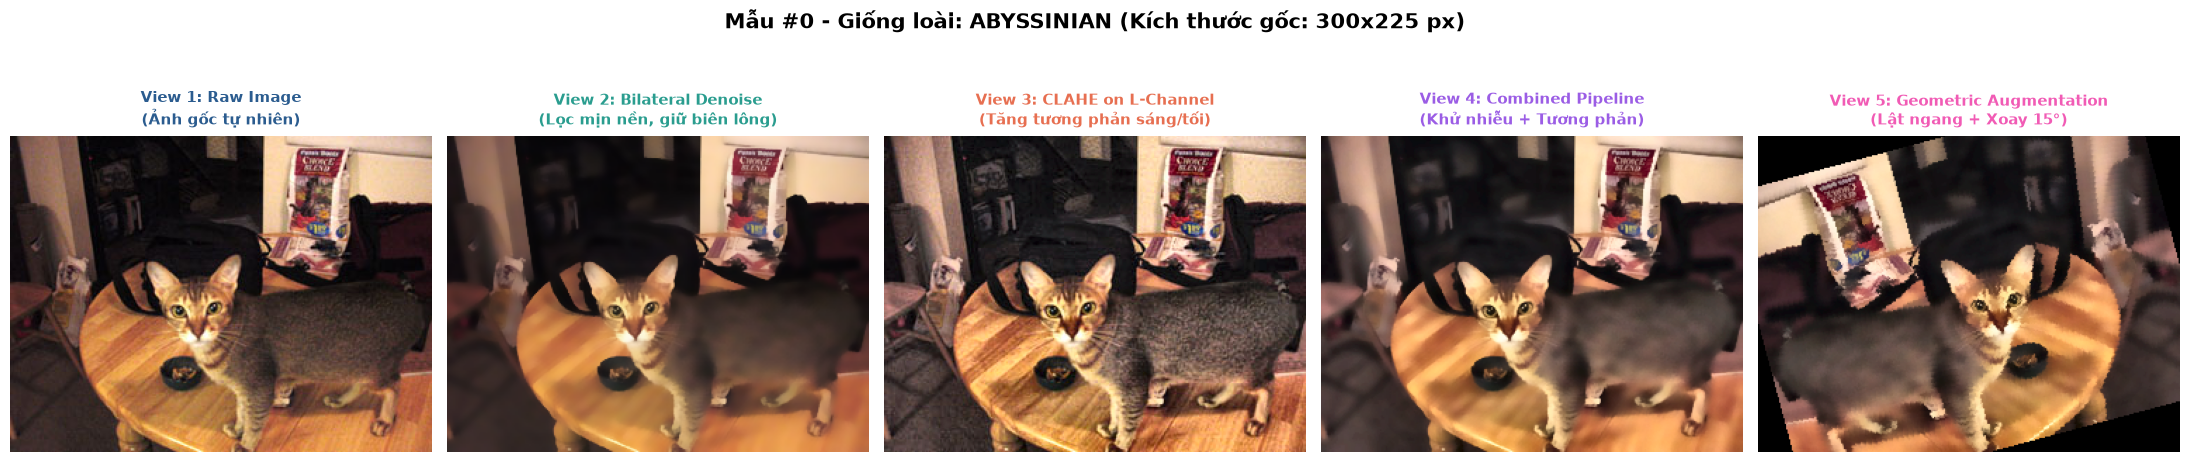

In [3]:
def display_5_views(pil_img: Image.Image, label_name: str = "", sample_idx: int = 0):
    """
    Hiển thị trực quan 5 ảnh trên 1 hàng kèm thông số chi tiết.
    """
    views_dict = generate_5_views(pil_img)
    
    fig, axes = plt.subplots(1, 5, figsize=(22, 5))
    fig.suptitle(f"Mẫu #{sample_idx} - Giống loài: {label_name.upper()} (Kích thước gốc: {pil_img.size[0]}x{pil_img.size[1]} px)", 
                 fontsize=15, fontweight='bold', y=1.03)
    
    colors = ['#2b5c8f', '#2a9d8f', '#e76f51', '#9b5de5', '#f15bb5']
    
    for ax, (title, (v_img, desc)), color in zip(axes, views_dict.items(), colors):
        ax.imshow(v_img)
        ax.set_title(f"{title}\n({desc})", fontsize=11, fontweight='semibold', color=color, pad=8)
        ax.axis('off')
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(2)
            spine.set_visible(True)
            
    plt.tight_layout()
    plt.show()

# Thử nghiệm trên mẫu đầu tiên của dataset
sample_img, sample_lbl = pets_test[0]
sample_breed = class_names[sample_lbl]
display_5_views(sample_img, label_name=sample_breed, sample_idx=0)


Đang tiến hành trích xuất và hiển thị 5 góc nhìn cho 5 mẫu ảnh...

--- [Ảnh 1/5] Mẫu ID #15: Abyssinian ---


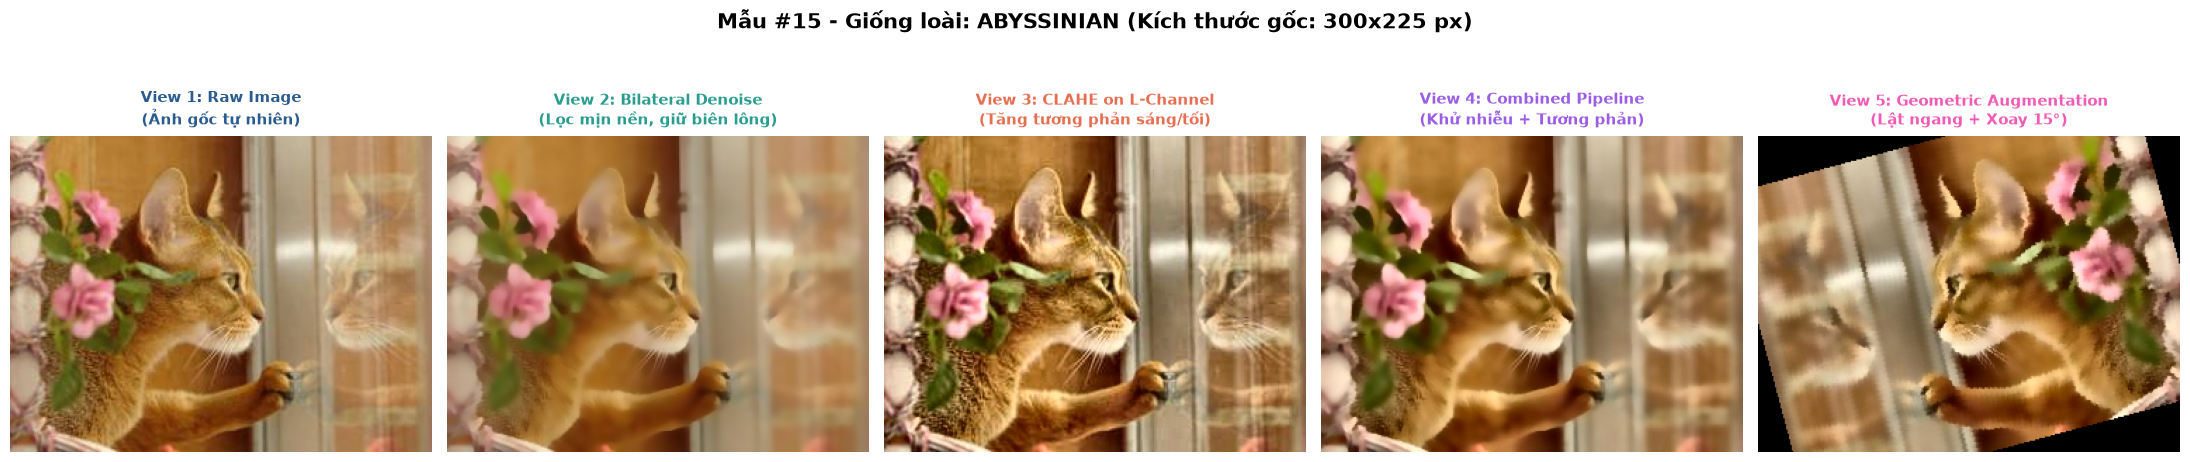

--- [Ảnh 2/5] Mẫu ID #120: American Bulldog ---


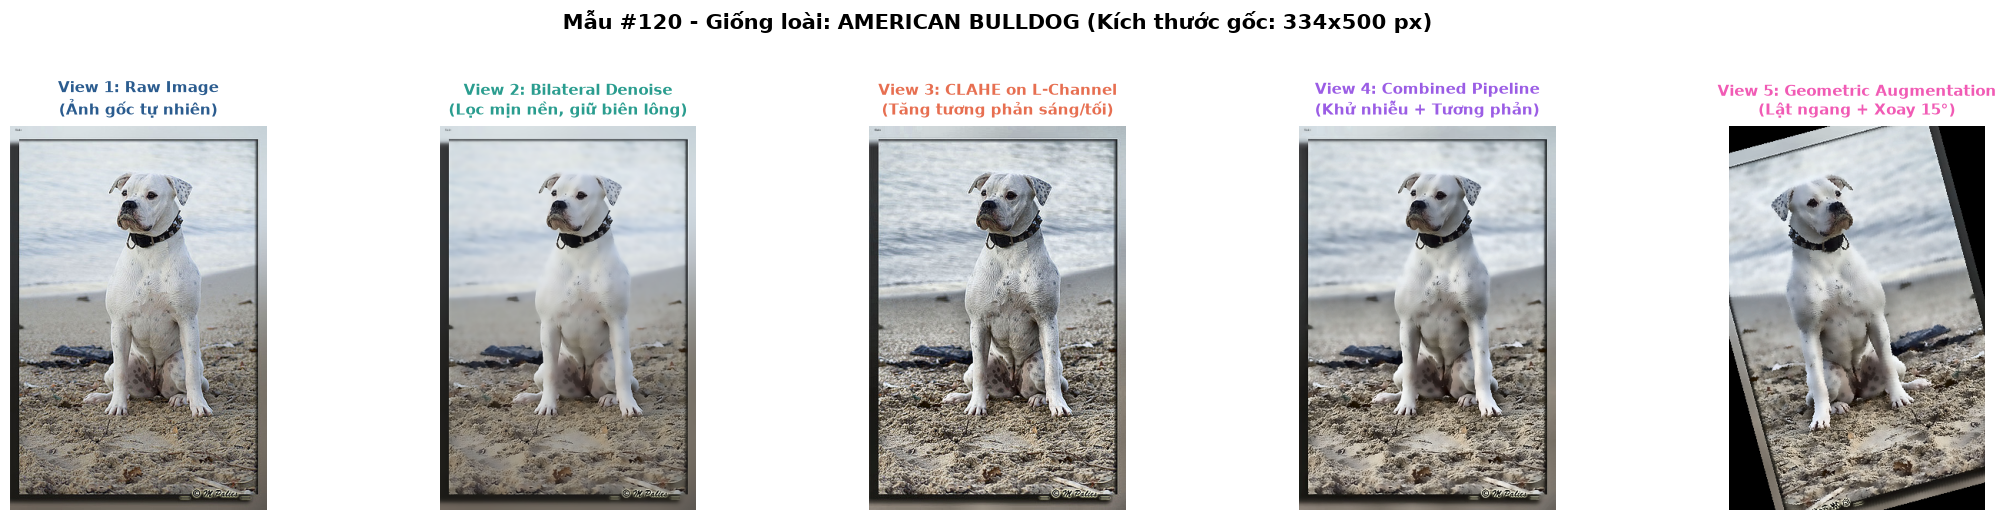

--- [Ảnh 3/5] Mẫu ID #350: Basset Hound ---


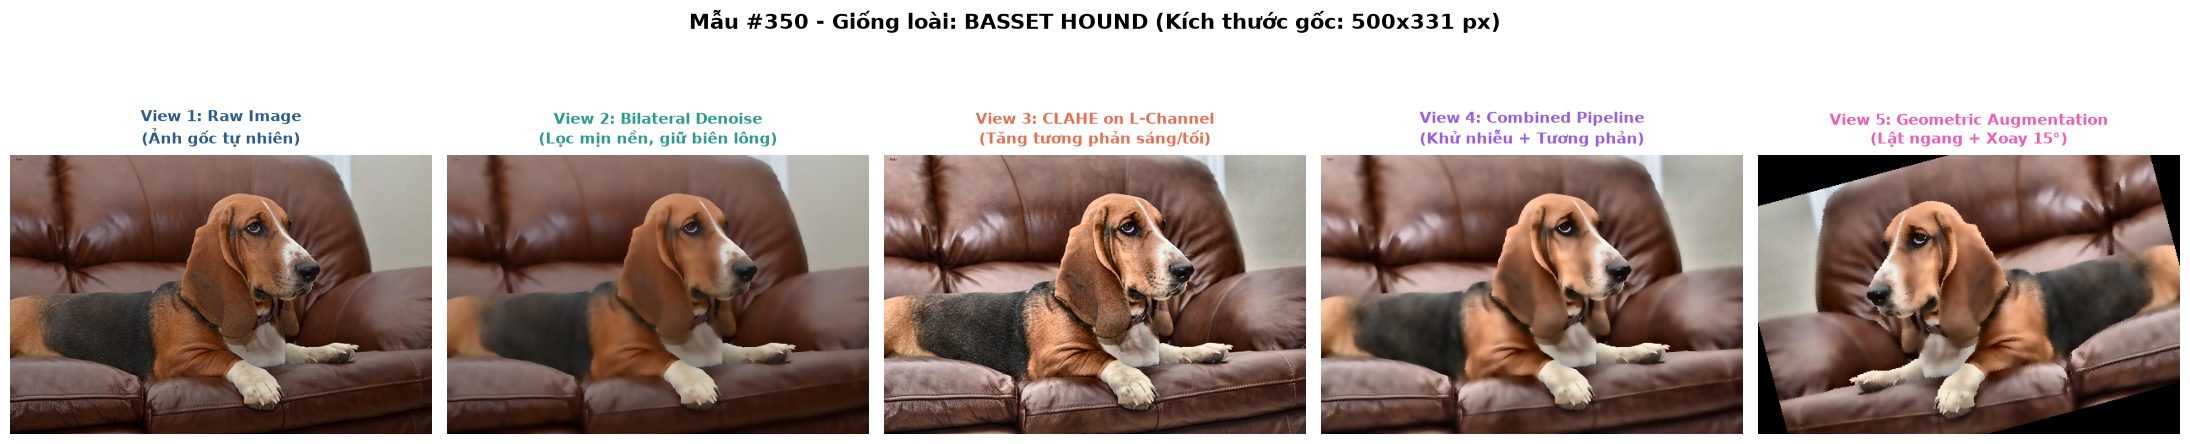

--- [Ảnh 4/5] Mẫu ID #780: Bombay ---


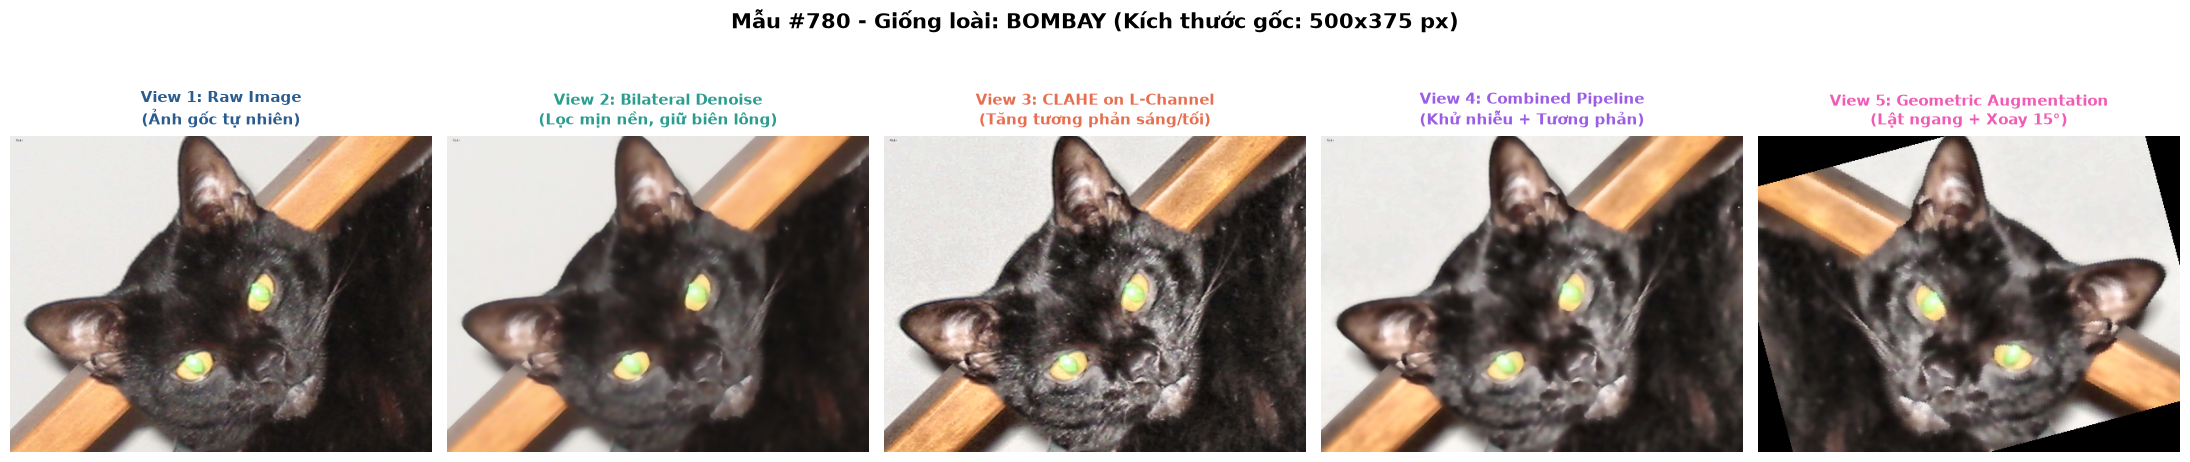

--- [Ảnh 5/5] Mẫu ID #1500: Great Pyrenees ---


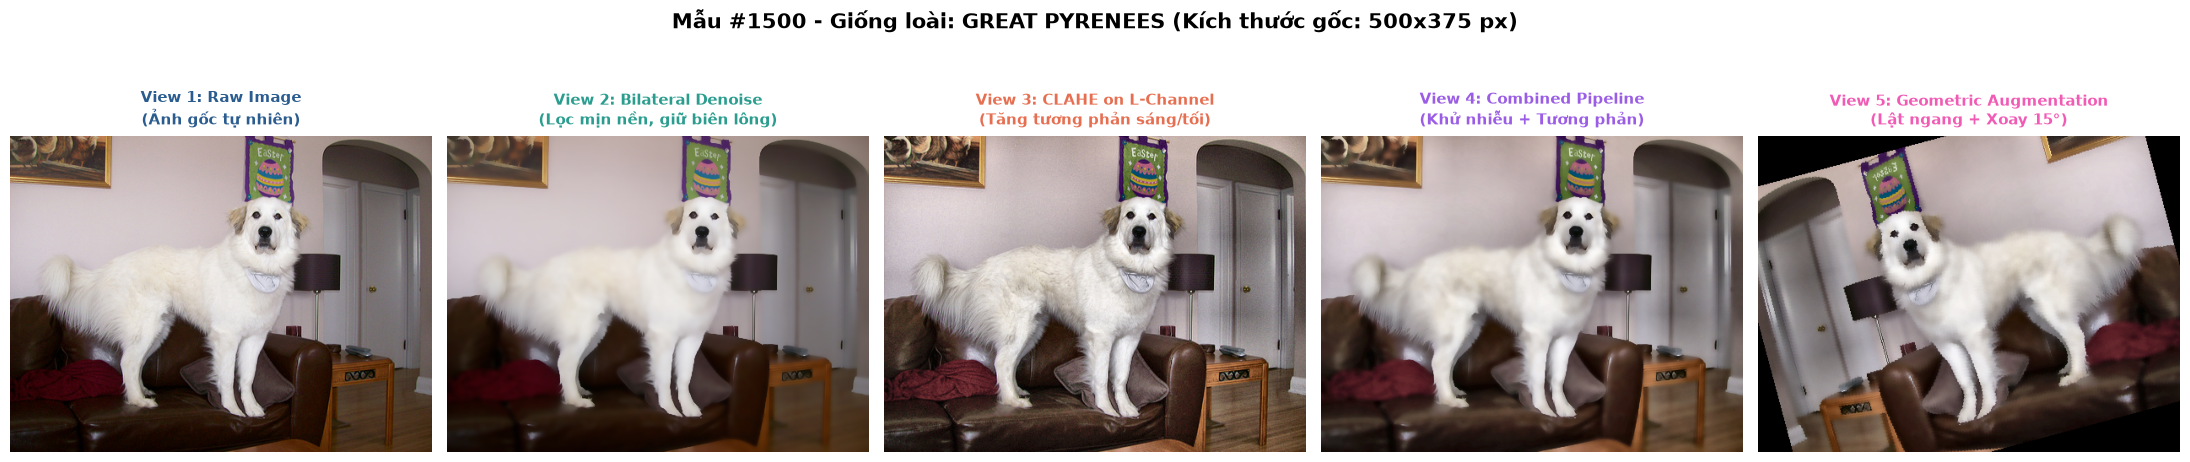

In [4]:
# ==============================================================================
# CHẠY QUA NHIỀU MẪU ẢNH VÀ IN RA ĐẦY ĐỦ 5 GÓC NHÌN CHO TỪNG MẪU
# ==============================================================================

# Chọn 5 mẫu ảnh đại diện từ các giống chó và mèo khác nhau
sample_indices = [15, 120, 350, 780, 1500]

print(f"Đang tiến hành trích xuất và hiển thị 5 góc nhìn cho {len(sample_indices)} mẫu ảnh...\n")

for i, idx in enumerate(sample_indices):
    img, lbl = pets_test[idx]
    breed = class_names[lbl]
    print(f"--- [Ảnh {i+1}/{len(sample_indices)}] Mẫu ID #{idx}: {breed} ---")
    display_5_views(img, label_name=breed, sample_idx=idx)


In [5]:
# ==============================================================================
# SO SÁNH SUY DIỄN ZERO-SHOT CLIP: TỪNG VIEW ĐƠN LẺ VS TTA ENSEMBLE
# ==============================================================================

# 1. Trích xuất text embeddings cho 37 giống loài
with torch.no_grad():
    text_inputs = processor(text=class_names, return_tensors="pt", padding=True).to(device)
    text_features = model.get_text_features(**text_inputs)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)

def evaluate_sample_views(pil_img: Image.Image, true_label: str):
    """
    Đánh giá độ tin cậy và dự đoán của từng View so với TTA Ensemble.
    """
    views_dict = generate_5_views(pil_img)
    view_features = []
    
    print(f"\n{'='*75}")
    print(f"KẾT QUẢ DỰ ĐOÁN ZERO-SHOT CHO MẪU: {true_label.upper()}")
    print(f"{'='*75}")
    print(f"{ 'Góc Nhìn (View)':<35} | {'Dự Đoán Top-1':<20} | {'Độ Tin Cậy':<10} | {'Kết Quả'}")
    print(f"{'-'*35}-+-{'-'*20}-+-{'-'*10}-+-{'-'*10}")
    
    with torch.no_grad():
        for title, (v_img, _) in views_dict.items():
            px = processor(images=v_img, return_tensors="pt")["pixel_values"].to(device)
            f = model.get_image_features(pixel_values=px)
            f = f / f.norm(dim=-1, keepdim=True)
            view_features.append(f)
            
            # Tính tương đồng Cosine
            sim = (f @ text_features.t())[0]
            prob = torch.softmax(sim * 100.0, dim=-1)
            pred_idx = sim.argmax().item()
            pred_name = class_names[pred_idx]
            conf = prob[pred_idx].item() * 100
            status = "[ĐÚNG]" if pred_name == true_label else "[SAI]"
            
            print(f"{title:<35} | {pred_name:<20} | {conf:6.2f}%    | {status}")
        
        # TTA Feature (Trung bình cộng 5 vector)
        tta_f = torch.stack(view_features, dim=0).mean(dim=0)
        tta_f = tta_f / tta_f.norm(dim=-1, keepdim=True)
        sim_tta = (tta_f @ text_features.t())[0]
        prob_tta = torch.softmax(sim_tta * 100.0, dim=-1)
        pred_tta_idx = sim_tta.argmax().item()
        pred_tta_name = class_names[pred_tta_idx]
        conf_tta = prob_tta[pred_tta_idx].item() * 100
        status_tta = "[ĐÚNG]" if pred_tta_name == true_label else "[SAI]"
        
        print(f"{'-'*75}")
        print(f"{'[TỔNG HỢP] TTA Ensemble (5 Views)':<35} | {pred_tta_name:<20} | {conf_tta:6.2f}%    | {status_tta}")
        print(f"{'='*75}\n")

# Đánh giá thử nghiệm trên 2 mẫu ảnh
for test_idx in [15, 350]:
    img, lbl = pets_test[test_idx]
    evaluate_sample_views(img, class_names[lbl])



KẾT QUẢ DỰ ĐOÁN ZERO-SHOT CHO MẪU: ABYSSINIAN
Góc Nhìn (View)                     | Dự Đoán Top-1        | Độ Tin Cậy | Kết Quả
------------------------------------+----------------------+------------+-----------
View 1: Raw Image                   | Abyssinian           |  99.36%    | [ĐÚNG]
View 2: Bilateral Denoise           | Abyssinian           |  97.72%    | [ĐÚNG]
View 3: CLAHE on L-Channel          | Abyssinian           |  97.33%    | [ĐÚNG]


View 4: Combined Pipeline           | Abyssinian           |  97.09%    | [ĐÚNG]
View 5: Geometric Augmentation      | Abyssinian           |  90.99%    | [ĐÚNG]
---------------------------------------------------------------------------
[TỔNG HỢP] TTA Ensemble (5 Views)   | Abyssinian           |  98.62%    | [ĐÚNG]


KẾT QUẢ DỰ ĐOÁN ZERO-SHOT CHO MẪU: BASSET HOUND
Góc Nhìn (View)                     | Dự Đoán Top-1        | Độ Tin Cậy | Kết Quả
------------------------------------+----------------------+------------+-----------
View 1: Raw Image                   | Basset Hound         |  98.11%    | [ĐÚNG]
View 2: Bilateral Denoise           | Basset Hound         |  95.40%    | [ĐÚNG]
View 3: CLAHE on L-Channel          | Basset Hound         |  96.75%    | [ĐÚNG]
View 4: Combined Pipeline           | Basset Hound         |  94.28%    | [ĐÚNG]
View 5: Geometric Augmentation      | Basset Hound         |  90.23%    | [ĐÚNG]
-----------------------------------------------------------